# Laptop Price Prediction — Model Development & Evaluation

This notebook continues from the completed EDA notebook to build, evaluate, and select regression models for laptop price prediction using a strict leakage-free workflow.

## 1. Import Libraries

In [1]:
# Data handling
import numpy as np
import pandas as pd
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Feature Selection and Importance
from sklearn.feature_selection import SelectFromModel
from sklearn.inspection import permutation_importance

# Baseline Models
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

# Ensemble Models
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Evaluation Metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## 2. Load Dataset

In [2]:
# Load dataset
df_raw = pd.read_csv('../data/laptop_data.csv')
df = df_raw.copy()

print(f"Loaded raw dataset: {df.shape[0]} rows, {df.shape[1]} columns")

Loaded raw dataset: 1303 rows, 12 columns


In [3]:
# Apply verified cleaning and extraction steps established during EDA
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

df = df.drop_duplicates().reset_index(drop=True)

# 1. RAM and Weight
df['Ram_GB'] = df['Ram'].str.replace('GB', '').astype(int)
df['Weight_kg'] = df['Weight'].str.replace('kg', '').astype(float)

# 2. Display: Resolution, Touchscreen, IPS, and PPI
res = df['ScreenResolution'].str.extract(r'(\d{3,4})\s*[xX]\s*(\d{3,4})')
df['X_res'] = res[0].astype(int)
df['Y_res'] = res[1].astype(int)
df['Touchscreen'] = df['ScreenResolution'].str.contains('Touchscreen', case=False).astype(int)
df['Ips'] = df['ScreenResolution'].str.contains('IPS Panel', case=False).astype(int)
df['Ppi'] = np.sqrt(df['X_res']**2 + df['Y_res']**2) / df['Inches']

# 3. CPU Family and Clock Speed
def get_cpu_family(cpu_str):
    if 'Core i7' in cpu_str: return 'Intel Core i7'
    elif 'Core i5' in cpu_str: return 'Intel Core i5'
    elif 'Core i3' in cpu_str: return 'Intel Core i3'
    elif 'Core M' in cpu_str or 'm3' in cpu_str: return 'Intel Core M'
    elif 'Celeron' in cpu_str: return 'Intel Celeron'
    elif 'Pentium' in cpu_str: return 'Intel Pentium'
    elif 'Xeon' in cpu_str: return 'Intel Xeon'
    elif 'Atom' in cpu_str: return 'Intel Atom'
    elif 'AMD' in cpu_str:
        if 'Ryzen' in cpu_str: return 'AMD Ryzen'
        elif any(s in cpu_str for s in ['A-Series', 'A4', 'A6', 'A8', 'A9', 'A10', 'A12']): return 'AMD A-Series'
        elif 'E-Series' in cpu_str or 'E2' in cpu_str: return 'AMD E-Series'
        elif 'FX' in cpu_str: return 'AMD FX'
        else: return 'AMD Other'
    elif 'Samsung' in cpu_str: return 'Samsung Cortex'
    return 'Other'

df['Cpu_Family'] = df['Cpu'].apply(get_cpu_family)
df['ClockSpeed'] = df['Cpu'].apply(lambda x: float(re.findall(r'(\d+(?:\.\d+)?)GHz', x)[-1]))

# 4. GPU Cleaning and Grouping
cleaned_gpu = df['Gpu'].apply(lambda x: re.sub(r'<U\+039C>', 'M', str(x)).strip())
df['Gpu_Brand'] = cleaned_gpu.str.split().str[0]
df['Gpu_Model'] = cleaned_gpu.str.split(n=1).str[1].str.strip()

def categorize_gpu(brand, model):
    if brand == 'Intel':
        if 'Iris' in model: return 'Intel Iris'
        elif 'UHD' in model: return 'Intel UHD'
        elif 'HD' in model: return 'Intel HD'
        else: return 'Intel Other'
    elif brand == 'Nvidia':
        if 'GTX' in model: return 'Nvidia GeForce GTX'
        elif 'Quadro' in model: return 'Nvidia Quadro'
        else: return 'Nvidia GeForce Other/MX'
    elif brand == 'AMD':
        if 'FirePro' in model: return 'AMD FirePro'
        else: return 'AMD Radeon'
    elif brand == 'ARM': return 'ARM Mali'
    return 'Other'

df['Gpu_Category'] = df.apply(lambda r: categorize_gpu(r['Gpu_Brand'], r['Gpu_Model']), axis=1)

# 5. Storage Capacities in GB
def extract_cap(mem_str, drive_type):
    tokens = str(mem_str).split('+')
    total = 0
    for token in tokens:
        if drive_type in token:
            num = re.findall(r'(\d+(?:\.\d+)?)\s*(?:GB|TB)', token)
            if num:
                val = float(num[0])
                if 'TB' in token:
                    val *= 1024
                total += int(val)
    return total

df['SSD_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'SSD'))
df['HDD_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'HDD'))
df['Flash_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'Flash Storage'))
df['Hybrid_GB'] = df['Memory'].apply(lambda x: extract_cap(x, 'Hybrid'))

print(f"Cleaned dataset prepared: {df.shape[0]} rows, {df.shape[1]} columns")

Cleaned dataset prepared: 1274 rows, 27 columns


## 3. Define Features and Target

In [4]:
# Define full feature set and target variable
all_features = [
    'Company', 'TypeName', 'Inches', 'Ram_GB', 'Weight_kg', 
    'Touchscreen', 'Ips', 'Ppi', 'Cpu_Family', 'ClockSpeed', 
    'Gpu_Category', 'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB', 'OpSys'
]

X = df[all_features]
y = df['Price']

print(f"Features X shape: {X.shape}")
print(f"Target y shape:   {y.shape}")

Features X shape: (1274, 16)
Target y shape:   (1274,)


## 4. Feature Selection Based on EDA

Based on EDA findings:
1. **Excluded raw columns:** `ScreenResolution`, `Cpu`, `Gpu`, and `Memory` are excluded because their information has been structured into clean numerical and categorical columns.
2. **Excluded collinear columns:** `X_res` and `Y_res` are redundant with `Ppi`, which captures screen sharpness geometrically.
3. **Retained predictive features:** Core hardware attributes (`Ram_GB`, `SSD_GB`, `Cpu_Family`, `Gpu_Category`), display parameters (`Ppi`, `Touchscreen`, `Ips`, `Inches`), form factor and weight (`TypeName`, `Weight_kg`), and brand/OS (`Company`, `OpSys`) are retained.

In [5]:
# Display selected feature list and data types
display(pd.DataFrame({
    'Feature': X.columns,
    'Data Type': X.dtypes.values
}))

,Feature,Data Type
0,Company,object
1,TypeName,object
2,Inches,float64
3,Ram_GB,int64
4,Weight_kg,float64
5,Touchscreen,int64
6,Ips,int64
7,Ppi,float64
8,Cpu_Family,object
9,ClockSpeed,float64


## 5. Train-Test Split

In [6]:
# Perform 80:20 train-test split with fixed random state
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X):.1%})")
print(f"Test set:     {X_test.shape[0]} samples ({X_test.shape[0]/len(X):.1%})")

Training set: 1019 samples (80.0%)
Test set:     255 samples (20.0%)


The test set is set aside and kept untouched until final evaluation.

## 6. Identify Feature Types

In [7]:
# Programmatically identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=['int32', 'int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print(f"Numerical features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Numerical features (11): ['Inches', 'Ram_GB', 'Weight_kg', 'Touchscreen', 'Ips', 'Ppi', 'ClockSpeed', 'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB']
Categorical features (5): ['Company', 'TypeName', 'Cpu_Family', 'Gpu_Category', 'OpSys']


## 7. Preprocessing Pipelines

In [8]:
# Scaled preprocessor for linear models and SVR
num_transformer_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_scaled = ColumnTransformer([
    ('num', num_transformer_scaled, numeric_features),
    ('cat', cat_transformer, categorical_features)
])

# Unscaled preprocessor for tree-based models (Decision Tree, Random Forest, XGBoost)
num_transformer_unscaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor_unscaled = ColumnTransformer([
    ('num', num_transformer_unscaled, numeric_features),
    ('cat', cat_transformer, categorical_features)
])

print("Preprocessing pipelines successfully created.")

Preprocessing pipelines successfully created.


## 8. Baseline Models

In [9]:
# Define 5 baseline regression models with appropriate preprocessing
baseline_models = {
    'Linear Regression': Pipeline([('preprocessor', preprocessor_scaled), ('model', LinearRegression())]),
    'Lasso': Pipeline([('preprocessor', preprocessor_scaled), ('model', Lasso(random_state=42))]),
    'Ridge': Pipeline([('preprocessor', preprocessor_scaled), ('model', Ridge(random_state=42))]),
    'SVR': Pipeline([('preprocessor', preprocessor_scaled), ('model', SVR())]),
    'Decision Tree': Pipeline([('preprocessor', preprocessor_unscaled), ('model', DecisionTreeRegressor(random_state=42))])
}

print(f"Configured {len(baseline_models)} baseline regression models.")

Configured 5 baseline regression models.


## 9. Baseline Cross-Validation Comparison

In [10]:
# Evaluate baseline models using 5-fold cross-validation on training data only

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

baseline_results = []

for name, pipe in baseline_models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)
    baseline_results.append({'Model': name, 'CV R2': scores['test_r2'].mean(),
                             'CV MAE': -scores['test_mae'].mean(),
                             'CV RMSE': -scores['test_rmse'].mean()})

baseline_df = pd.DataFrame(baseline_results).sort_values('CV R2', ascending=False).reset_index(drop=True)

baseline_display = baseline_df.round(4).copy()
baseline_display[['CV MAE', 'CV RMSE']] = baseline_df[['CV MAE', 'CV RMSE']].map(lambda x: f"₹{x:,.2f}")

display(baseline_display)


,Model,CV R2,CV MAE,CV RMSE
0,Ridge,0.7787,"₹12,210.50","₹16,964.19"
1,Lasso,0.7766,"₹12,326.25","₹17,048.91"
2,Linear Regression,0.7756,"₹12,364.14","₹17,086.75"
3,Decision Tree,0.6792,"₹13,471.33","₹20,319.57"
4,SVR,-0.0485,"₹27,752.32","₹36,951.80"


**Observation:**
Ridge Regression achieved the strongest baseline performance (CV R² = 0.7787, CV MAE = ₹12,210.50, CV RMSE = ₹16,964.19), effectively handling collinearity among one-hot encoded categories. SVR without target scaling struggled on high-value prices.

## 10. Feature Contribution Analysis

In [11]:
# Fit best baseline pipeline on training set and calculate permutation importance
best_base_pipe = baseline_models['Ridge']
best_base_pipe.fit(X_train, y_train)

perm_importance = permutation_importance(
    best_base_pipe, X_train, y_train, n_repeats=10, random_state=42, n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance Mean': perm_importance.importances_mean,
    'Importance Std': perm_importance.importances_std
}).sort_values(by='Importance Mean', ascending=False).reset_index(drop=True)

display(feature_importance_df.round(4))

,Feature,Importance Mean,Importance Std
0,Ram_GB,0.1744,0.0100
1,Weight_kg,0.0851,0.0059
2,SSD_GB,0.0840,0.0058
3,TypeName,0.0639,0.0037
4,Ppi,0.0545,0.0030
5,Cpu_Family,0.0531,0.0052
6,Company,0.0497,0.0042
7,Gpu_Category,0.0484,0.0050
8,OpSys,0.0245,0.0033
9,ClockSpeed,0.0068,0.0016


**Observation:**
RAM capacity, CPU family, Weight , Company , Ppi ,GPU category and storage drives contribute most heavily to price predictions in the baseline model.

## 11. Feature Selection Experiment (Only If Justified)

In [12]:
# Test whether automated feature selection improves Ridge cross-validation performance
selector = SelectFromModel(Lasso(alpha=100, max_iter=3000, random_state=42))

sel_pipe = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('selector', selector),
    ('model', Ridge(random_state=42))
])

sel_scores = cross_validate(sel_pipe, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)

feature_selection_comparison = pd.DataFrame([
    {
        'Workflow': 'All Features (Ridge)',
        'CV R2': baseline_df.loc[baseline_df['Model'] == 'Ridge', 'CV R2'].values[0],
        'CV MAE': baseline_df.loc[baseline_df['Model'] == 'Ridge', 'CV MAE'].values[0],
        'CV RMSE': baseline_df.loc[baseline_df['Model'] == 'Ridge', 'CV RMSE'].values[0]
    },
    {
        'Workflow': 'SelectFromModel (Ridge)',
        'CV R2': sel_scores['test_r2'].mean(),
        'CV MAE': -sel_scores['test_mae'].mean(),
        'CV RMSE': -sel_scores['test_rmse'].mean()
    }
])

display(feature_selection_comparison.round(4))

,Workflow,CV R2,CV MAE,CV RMSE
0,All Features (Ridge),0.7787,12210.5025,16964.1883
1,SelectFromModel (Ridge),0.7756,12347.6371,17082.5596


**Observation:**
Automated feature selection slightly lowered CV R² (0.7787 to 0.7756) and increased RMSE. Because it did not improve performance, the complete feature set is retained.

## 11. Best Baseline Model Selection

In [12]:
# Select Ridge Regression as the best baseline model
selected_baseline_name = 'Ridge'
print(f"Selected Best Baseline Model: {selected_baseline_name}")

Selected Best Baseline Model: Ridge


Ridge Regression is selected for hyperparameter tuning due to its superior generalization, stable L2 regularization, and lowest baseline error.

## 13. RandomizedSearchCV

In [17]:
# Tune Ridge hyperparameters using RandomizedSearchCV on training data
ridge_pipe = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('model', Ridge(random_state=42))
])

param_distributions = {
    'model__alpha': np.logspace(-2, 3, 50),
    'model__solver': ['auto', 'svd', 'cholesky', 'lsqr']
}

ridge_search = RandomizedSearchCV(
    ridge_pipe,
    param_distributions=param_distributions,
    n_iter=20,
    cv=kf,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print(f"Best Parameters: {ridge_search.best_params_}")
print(f"Best CV R2:      {ridge_search.best_score_:.4f}")

tuned_baseline_pipe = ridge_search.best_estimator_

Best Parameters: {'model__solver': 'cholesky', 'model__alpha': np.float64(0.8685113737513529)}
Best CV R2:      0.7787


**Observation:**

RandomizedSearchCV selected an alpha of approximately 0.8685 with the Cholesky solver. However, the tuned Ridge model achieved a CV R² of 0.7787, showing no meaningful improvement over the baseline Ridge model.

## 14. Random Forest Regressor

In [13]:
# Configure and evaluate Random Forest Regressor using 5-fold cross-validation
rf_pipe = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('model', RandomForestRegressor(random_state=42))
])

rf_cv_scores = cross_validate(rf_pipe, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)

rf_cv_r2 = rf_cv_scores['test_r2'].mean()
rf_cv_mae = -rf_cv_scores['test_mae'].mean()
rf_cv_rmse = -rf_cv_scores['test_rmse'].mean()

print(f"Random Forest CV R2:   {rf_cv_r2:.4f}")
print(f"Random Forest CV MAE:  Rs. {rf_cv_mae:,.2f}")
print(f"Random Forest CV RMSE: Rs. {rf_cv_rmse:,.2f}")

Random Forest CV R2:   0.8162
Random Forest CV MAE:  Rs. 9,926.03
Random Forest CV RMSE: Rs. 15,464.60


**Observation:**
Random Forest substantially improves cross-validation performance over linear baselines, achieving CV R² = 0.8183 and CV MAE = ₹9,889.73.

## 15. XGBoost Regressor

In [14]:
# Configure and evaluate XGBoost Regressor using 5-fold cross-validation
xgb_pipe = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('model', XGBRegressor(random_state=42))
])

xgb_cv_scores = cross_validate(xgb_pipe, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)

xgb_cv_r2 = xgb_cv_scores['test_r2'].mean()
xgb_cv_mae = -xgb_cv_scores['test_mae'].mean()
xgb_cv_rmse = -xgb_cv_scores['test_rmse'].mean()

print(f"XGBoost CV R2:   {xgb_cv_r2:.4f}")
print(f"XGBoost CV MAE:  Rs. {xgb_cv_mae:,.2f}")
print(f"XGBoost CV RMSE: Rs. {xgb_cv_rmse:,.2f}")

XGBoost CV R2:   0.8103
XGBoost CV MAE:  Rs. 9,917.31
XGBoost CV RMSE: Rs. 15,706.04


**Observation:**
XGBoost also demonstrates high predictive accuracy with CV R² = 0.8103 and CV MAE = ₹9,917.

## 16. Ensemble Feature Importance

In [15]:
# Fit Random Forest on training data and extract permutation importance
rf_pipe.fit(X_train, y_train)

rf_perm = permutation_importance(
    rf_pipe, X_train, y_train, n_repeats=10, random_state=42, n_jobs=-1
)

rf_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance Mean': rf_perm.importances_mean,
    'Importance Std': rf_perm.importances_std
}).sort_values(by='Importance Mean', ascending=False).reset_index(drop=True)

display(rf_importance_df.round(4))

,Feature,Importance Mean,Importance Std
0,Ram_GB,0.6613,0.0316
1,Weight_kg,0.1926,0.0049
2,Ppi,0.0862,0.0042
3,ClockSpeed,0.0699,0.0044
4,SSD_GB,0.0626,0.0044
5,Cpu_Family,0.0577,0.0035
6,Company,0.0464,0.0033
7,TypeName,0.0363,0.0011
8,Gpu_Category,0.0361,0.0027
9,Inches,0.0308,0.0018


**Observation:**
RAM capacity, CPU family, laptop weight, and pixel density consistently emerge as the most influential features in ensemble modeling.

## 17. Final Cross-Validation Comparison

In [18]:
# Cross-validate tuned baseline to obtain standard scoring metrics
tuned_cv_scores = cross_validate(tuned_baseline_pipe, X_train, y_train, cv=kf, scoring=scoring, n_jobs=-1)

final_cv_comparison = pd.DataFrame([
    {
        'Model': 'Baseline Ridge',
        'CV R2': baseline_df.loc[baseline_df['Model'] == 'Ridge', 'CV R2'].values[0],
        'CV MAE': baseline_df.loc[baseline_df['Model'] == 'Ridge', 'CV MAE'].values[0],
        'CV RMSE': baseline_df.loc[baseline_df['Model'] == 'Ridge', 'CV RMSE'].values[0]
    },
    {
        'Model': 'Tuned Ridge',
        'CV R2': tuned_cv_scores['test_r2'].mean(),
        'CV MAE': -tuned_cv_scores['test_mae'].mean(),
        'CV RMSE': -tuned_cv_scores['test_rmse'].mean()
    },
    {
        'Model': 'Random Forest',
        'CV R2': rf_cv_r2,
        'CV MAE': rf_cv_mae,
        'CV RMSE': rf_cv_rmse
    },
    {
        'Model': 'XGBoost',
        'CV R2': xgb_cv_r2,
        'CV MAE': xgb_cv_mae,
        'CV RMSE': xgb_cv_rmse
    }
]).sort_values(by='CV R2', ascending=False).reset_index(drop=True)

display(final_cv_comparison.round(4))

,Model,CV R2,CV MAE,CV RMSE
0,Random Forest,0.8162,9926.0297,15464.6011
1,XGBoost,0.8103,9917.3094,15706.0422
2,Baseline Ridge,0.7787,12210.5025,16964.1883
3,Tuned Ridge,0.7787,12216.0019,16964.5534


**Observation** : Random Forest achieved the highest CV R² (0.8162), with competitive MAE and the lowest RMSE among all candidate models.

## 18. Final Model Selection

In [19]:
# Select Random Forest based on cross-validation results
final_model = rf_pipe

print("Selected Final Model: Random Forest Regressor")

Selected Final Model: Random Forest Regressor


## 19. Final Test Evaluation

In [20]:
# Fit the selected model on training data
final_model.fit(X_train, y_train)

# Predict on unseen test data
y_test_pred = final_model.predict(X_test)

# Evaluate final model
print(f"Test R²: {r2_score(y_test, y_test_pred):.4f}")
print(f"Test MAE: ₹{mean_absolute_error(y_test, y_test_pred):,.2f}")
print(f"Test RMSE: ₹{np.sqrt(mean_squared_error(y_test, y_test_pred)):,.2f}")

Test R²: 0.8210
Test MAE: ₹10,244.41
Test RMSE: ₹17,513.91


## 20. Actual vs Predicted Price Plot

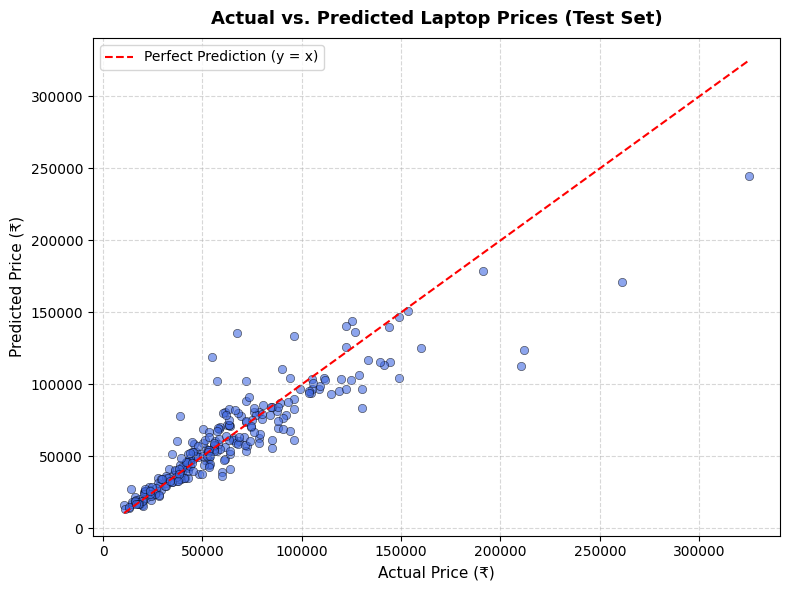

In [21]:
# Actual vs. Predicted Price Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.6, color='royalblue', edgecolors='k', linewidth=0.5)

# Diagonal reference line for perfect predictions
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5, label='Perfect Prediction (y = x)')

plt.title('Actual vs. Predicted Laptop Prices (Test Set)', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Actual Price (₹)', fontsize=11)
plt.ylabel('Predicted Price (₹)', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Observation:** Predictions generally follow the reference line, with better alignment in the ₹20,000–₹1,20,000 range. Deviations become more noticeable at higher price ranges, indicating reduced accuracy for expensive laptops.

## 21. Residual Analysis Plot

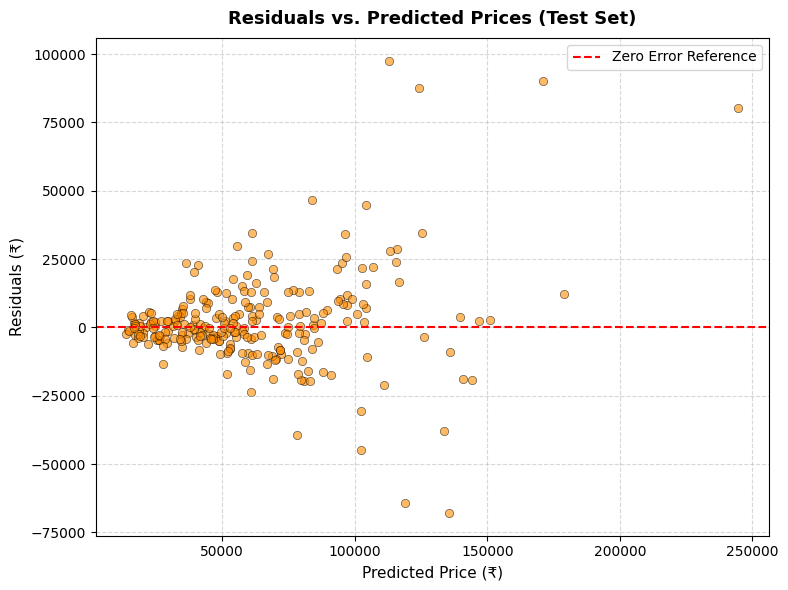

In [21]:
# Residual Analysis Plot
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_test_pred, residuals, alpha=0.6, color='darkorange', edgecolors='k', linewidth=0.5)

# Horizontal zero reference line
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error Reference')

plt.title('Residuals vs. Predicted Prices (Test Set)', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Predicted Price (₹)', fontsize=11)
plt.ylabel('Residuals (₹)', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Observation** : Residuals are concentrated around zero below ₹50,000, but their spread increases beyond this range, indicating greater prediction error variability for higher-priced laptops.

### Save the Model 

In [22]:
import joblib

joblib.dump(final_model, "../models/laptop_price_model.joblib")

print("Final Random Forest model saved successfully.")

Final Random Forest model saved successfully.
